In [1]:
# 1. Imports
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
faro = pd.read_csv("../data/faro_2021_2025.csv")
angra = pd.read_csv("../data/angra_2021_2025.csv")

## Faro Dataset Analysis

In [3]:
faro.head()

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2021-01-01T00:00,12.1,84,0.0,16.0
1,2021-01-01T01:00,11.6,83,0.0,13.7
2,2021-01-01T02:00,11.0,79,0.0,16.6
3,2021-01-01T03:00,10.4,83,0.0,17.1
4,2021-01-01T04:00,10.0,85,0.0,17.1


In [4]:
faro.sample(10)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
33232,2024-10-16T16:00,20.8,81,0.0,19.0
33753,2024-11-07T09:00,18.6,79,0.0,23.1
26715,2024-01-19T03:00,16.3,89,2.3,28.3
37693,2025-04-20T13:00,17.7,58,0.0,19.8
26616,2024-01-15T00:00,16.3,92,0.0,8.7
18552,2023-02-13T00:00,13.5,85,0.0,20.3
5106,2021-08-01T18:00,27.5,45,0.0,27.6
32719,2024-09-25T07:00,21.2,92,0.0,13.3
43502,2025-12-18T14:00,17.1,62,0.1,12.8
31093,2024-07-19T13:00,30.8,41,0.0,13.4


In [5]:
faro.shape

(43824, 5)

In [6]:
faro.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  43824 non-null  str    
 1   temperature_2m        43824 non-null  float64
 2   relative_humidity_2m  43824 non-null  int64  
 3   precipitation         43824 non-null  float64
 4   wind_speed_10m        43824 non-null  float64
dtypes: float64(3), int64(1), str(1)
memory usage: 1.7 MB


In [7]:
faro.isnull().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
dtype: int64

In [8]:
faro.duplicated().sum()

np.int64(0)

In [9]:
faro["time"] = pd.to_datetime(faro["time"])

In [10]:
faro["time"].min(), faro["time"].max()

(Timestamp('2021-01-01 00:00:00'), Timestamp('2025-12-31 23:00:00'))

In [11]:
faro["time"].is_monotonic_increasing

True

In [12]:
expected = pd.date_range(
    start=faro["time"].min(),
    end=faro["time"].max(),
    freq="h"
)

len(expected) - len(faro)

0

In [13]:
faro.describe().round(2)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
count,43824,43824.00,43824.00,43824.00,43824.00
mean,2023-07-02 23:29:59.999999,18.81,69.34,0.06,12.85
min,2021-01-01 00:00:00,2.50,8.00,0.00,0.00
25%,2022-04-02 11:45:00,14.80,57.00,0.00,7.60
50%,2023-07-02 23:30:00,18.40,71.00,0.00,11.90
75%,2024-10-01 11:15:00,22.60,84.00,0.00,17.10
max,2025-12-31 23:00:00,39.50,100.00,22.80,56.60
std,NaN,5.52,17.64,0.41,6.91


In [14]:
faro["rain_event"] = (faro["precipitation"] > 0).astype(int)

Related to rain_event now

In [15]:
faro["rain_event"].value_counts()

rain_event
0    39945
1     3879
Name: count, dtype: int64

In [16]:
faro["rain_event"].value_counts(normalize=True).mul(100).round(2)

rain_event
0    91.15
1     8.85
Name: proportion, dtype: float64

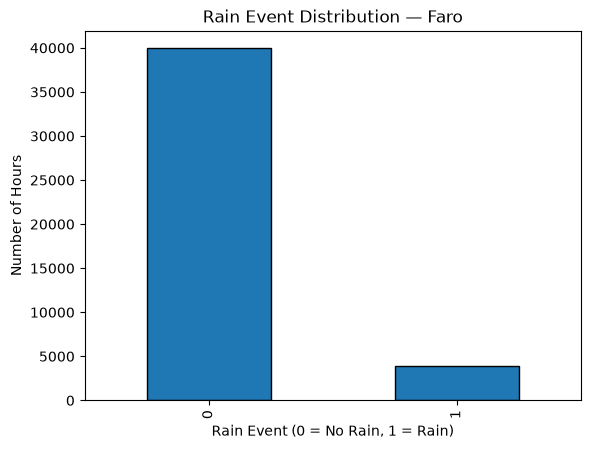

In [17]:
faro["rain_event"].value_counts().sort_index().plot(
    kind="bar",
    title="Rain Event Distribution — Faro", edgecolor="black"
)

plt.xlabel("Rain Event (0 = No Rain, 1 = Rain)")
plt.ylabel("Number of Hours")
plt.show()

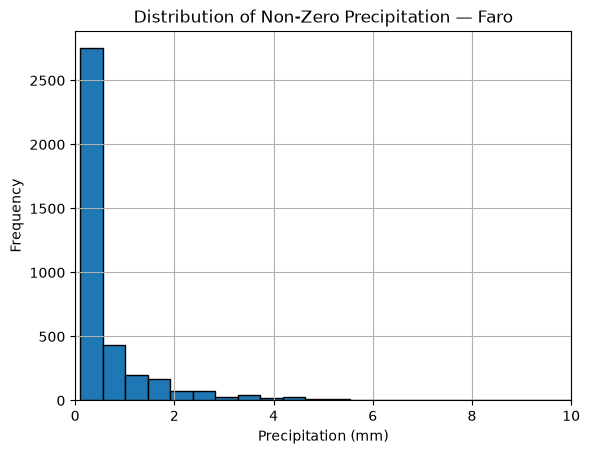

In [18]:
faro.loc[faro["precipitation"] > 0, "precipitation"].hist(bins=50, edgecolor="black")

plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency")
plt.xlim(0, 10)
plt.title("Distribution of Non-Zero Precipitation — Faro")
plt.show()

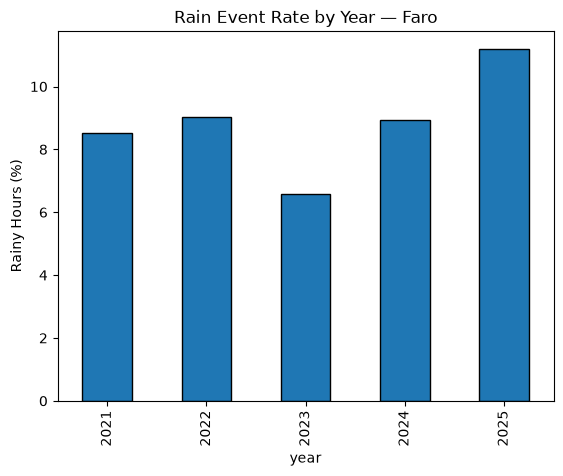

In [19]:
faro["year"] = faro["time"].dt.year

yearly_rain = faro.groupby("year")["rain_event"].mean() * 100

yearly_rain.plot(
    kind="bar",
    title="Rain Event Rate by Year — Faro", edgecolor="black"
)

plt.ylabel("Rainy Hours (%)")
plt.show()

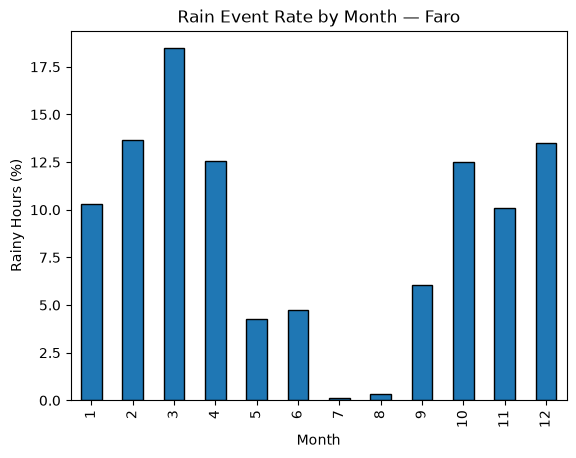

In [20]:
faro["month"] = faro["time"].dt.month

monthly_rain = faro.groupby("month")["rain_event"].mean() * 100

monthly_rain.plot(
    kind="bar",
    title="Rain Event Rate by Month — Faro", edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Rainy Hours (%)")
plt.show()

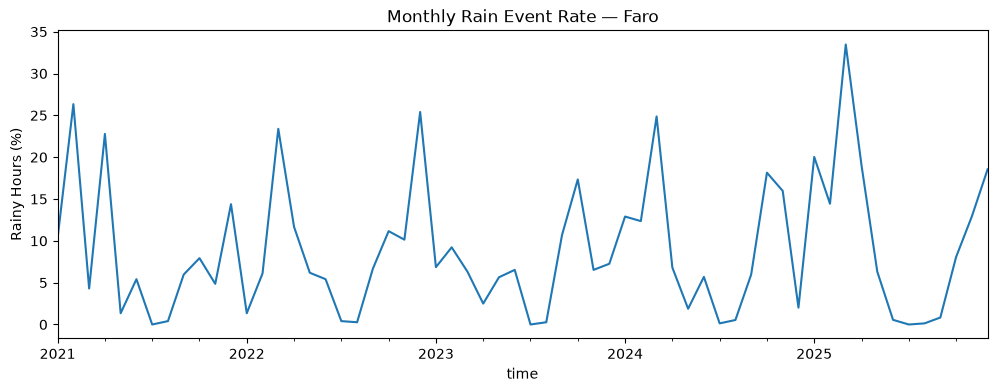

In [21]:
monthly = (
    faro
    .set_index("time")["rain_event"]
    .resample("ME")
    .mean() * 100
)

monthly.plot(
    figsize=(12, 4),
    title="Monthly Rain Event Rate — Faro"
)

plt.ylabel("Rainy Hours (%)")
plt.show()

## Angra Dataset Analysis

In [23]:
angra.head()

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2021-01-01T00:00,13.7,82,0.0,12.6
1,2021-01-01T01:00,13.7,83,0.0,13.4
2,2021-01-01T02:00,13.6,84,0.0,12.6
3,2021-01-01T03:00,13.4,86,0.0,12.6
4,2021-01-01T04:00,13.4,88,0.0,12.8


'text=\'f(angra.head()\nangra.sample(10)\nangra.shape\nangra.info()\nangra.isnull().sum()\nangra.duplicated().sum()\nangra["time"] = pd.to_datetime(angra["time"])\nangra["time"].min(), angra["time"].max()\nangra["time"].is_monotonic_increasing\nexpected = pd.date_range(\n    start=angra["time"].min(),\n    end=angra["time"].max(),\n    freq="h"\n)\n\nlen(expected) - len(angra)\nangra.describe().round(2)\nangra["rain_event"] = (angra["precipitation"] > 0).astype(int)\nangra["rain_event"].value_counts()\nangra["rain_event"].value_counts(normalize=True).mul(100).round(2)\nangra["rain_event"].value_counts().sort_index().plot(\n    kind="bar",\n    title="Rain Event Distribution — angra", edgecolor="black"\n)\n\nplt.xlabel("Rain Event (0 = No Rain, 1 = Rain)")\nplt.ylabel("Number of Hours")\nplt.show()\nangra.loc[angra["precipitation"] > 0, "precipitation"].hist(bins=50, edgecolor="black")\n\nplt.xlabel("Precipitation (mm)")\nplt.ylabel("Frequency")\nplt.xlim(0, 10)\nplt.title("Distribution